# New algorithm: Explainable Boosting Machine (EBM)
**Melanie Samaratunga · 269188K · Applied ML final assignment**

The assignment asks for a machine-learning algorithm **not covered in the lectures**. The lectures covered decision trees, Random Forest, AdaBoost, gradient boosting, XGBoost, LightGBM, CatBoost, SVM, voting and stacking. This notebook adds the **Explainable Boosting Machine** (Lou et al., 2013; Nori et al., 2019, InterpretML), which was not covered.

**Why EBM for this problem**
* It is a *glass-box* model: a generalised additive model with a few pairwise interactions (GA²M). Each feature's effect is a learned curve that can be read directly, so the explanation **is** the model, not an approximation of it (as SHAP and LIME are for CatBoost).
* It is trained with gradient boosting, so it can reach accuracy close to black-box tree ensembles on tabular data.
* It handles categorical features (brand, model family, town) and missing values natively.

**How it differs from standard models**
* **Linear regression:** also additive, but each effect is a straight line. EBM learns any curve shape, such as mileage mattering only below 100,000 km.
* **Decision tree / Random Forest / XGBoost / CatBoost:** each tree mixes all features, so the model can only be explained after the fact. EBM trains on **one feature at a time** in round-robin (cyclic boosting with a very low learning rate), so every feature's contribution stays separate and exact.
* **k-NN:** predicts from similar cars and needs a distance between categories. EBM learns a global, reusable effect for every category instead.

The evaluation is **identical** to the main notebook: same cleaning (`data_prep.py`), same grouped 80/20 split (seed 42), same 5-fold `GroupKFold` cross-validation for tuning, log-price target, and the same test metrics on the same 997 cars.

In [1]:
import json, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from interpret.glassbox import ExplainableBoostingRegressor
import interpret
from data_prep import load_raw, clean
import train
warnings.filterwarnings("ignore")
SEED, FIG = 42, "reports/figures"
print("interpret", interpret.__version__)

interpret 0.7.8


## 1. Same data and same leakage-safe split

In [2]:
df, _ = clean(load_raw("data/raw"), ref_year=2026)
FEATURES = train.FEATURES
CATS = ["Brand", "Family", "Gear", "Fuel", "Body", "Condition", "Country", "Location"]
X, y, groups = df[FEATURES], df["Price_mn"], df["listing_group"]
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
g_train = groups.iloc[tr_idx]
print("Train:", X_train.shape, "Test:", X_test.shape, "| group overlap:", len(set(g_train) & set(groups.iloc[te_idx])))

Train: (3976, 15) Test: (997, 15) | group overlap: 0


## 2. Tuning with 5-fold grouped cross-validation
No default parameters: the search covers the number of pairwise interactions, the learning rate, tree size per boosting step, minimum leaf size and smoothing. `outer_bags=4` (bagged EBMs averaged) keeps training time manageable on a 2-core machine.

In [3]:
feature_types = ["nominal" if c in CATS else "continuous" for c in FEATURES]
def ebm(**kw):
    return TransformedTargetRegressor(
        regressor=ExplainableBoostingRegressor(feature_types=feature_types, random_state=SEED, n_jobs=1, outer_bags=4, **kw),
        func=np.log, inverse_func=np.exp)

grid = {"regressor__interactions": [0, 5, 10], "regressor__learning_rate": [0.01, 0.03, 0.06],
        "regressor__max_leaves": [2, 3], "regressor__min_samples_leaf": [2, 4, 8], "regressor__smoothing_rounds": [0, 200]}
search = RandomizedSearchCV(ebm(), grid, n_iter=8, cv=GroupKFold(n_splits=5), scoring={"r2": "r2", "mae": "neg_mean_absolute_error"},
                            refit="r2", random_state=SEED, n_jobs=-1)
t0 = time.time(); search.fit(X_train, y_train, groups=g_train)
i, cr = search.best_index_, search.cv_results_
cv_r2, cv_sd, cv_mae = cr["mean_test_r2"][i], cr["std_test_r2"][i], -cr["mean_test_mae"][i]
best_params = {k.replace("regressor__", ""): v for k, v in search.best_params_.items()}
print(f"EBM: CV R2 = {cv_r2:.4f} ± {cv_sd:.4f}  ({time.time()-t0:.0f}s)\nbest params: {best_params}")

EBM: CV R2 = 0.8851 ± 0.0386  (198s)
best params: {'smoothing_rounds': 200, 'min_samples_leaf': 2, 'max_leaves': 3, 'learning_rate': 0.06, 'interactions': 5}


## 3. Held-out test set (the same 997 cars)

In [4]:
model = search.best_estimator_
pred = model.predict(X_test)
err = np.abs(pred - y_test) / y_test
ebm_test = {"R2": r2_score(y_test, pred), "MAE_mn": mean_absolute_error(y_test, pred),
            "RMSE_mn": mean_squared_error(y_test, pred) ** 0.5, "MAPE_%": 100 * mean_absolute_percentage_error(y_test, pred),
            "R2_log": r2_score(np.log(y_test), np.log(pred))}
print({k: round(v, 4) for k, v in ebm_test.items()})
print(f"median error {100*np.median(err):.1f}%  ·  within ±10%: {100*(err<=0.1).mean():.1f}%  ·  within ±20%: {100*(err<=0.2).mean():.1f}%")

{'R2': 0.92, 'MAE_mn': 0.9137, 'RMSE_mn': 1.8048, 'MAPE_%': 9.8037, 'R2_log': 0.9518}
median error 6.7%  ·  within ±10%: 65.6%  ·  within ±20%: 89.8%


**Comparison with the models from the main notebook** (EBM rows added to the saved results).

In [5]:
NAME = "EBM (Explainable Boosting)"
cv_df = pd.read_csv("reports/cv_results.csv").query("model != @NAME")
cv_df = pd.concat([cv_df, pd.DataFrame([{"model": NAME, "CV_R2": cv_r2, "CV_R2_sd": cv_sd, "CV_MAE_mn": cv_mae}])])
cv_df = cv_df.sort_values("CV_R2", ascending=False).round(4)
cv_df.to_csv("reports/cv_results.csv", index=False)

test_df = pd.read_csv("reports/test_results.csv", index_col=0).drop(index=NAME, errors="ignore")
test_df.loc[NAME] = ebm_test
test_df = test_df.sort_values("R2", ascending=False).round(4)
test_df.to_csv("reports/test_results.csv")

tj = [r for r in json.load(open("models/test_results.json")) if r["model"] != NAME]
tj.append({"model": NAME, **{k: round(float(v), 6) for k, v in ebm_test.items()}})
json.dump(tj, open("models/test_results.json", "w"), indent=1)

display(cv_df.set_index("model")); display(test_df[["R2", "MAE_mn", "RMSE_mn", "MAPE_%"]])

,CV_R2,CV_R2_sd,CV_MAE_mn
model,,,
EBM (Explainable Boosting),0.8851,0.0386,0.9038
CatBoost,0.8845,0.0497,0.8296
XGBoost,0.8828,0.0735,0.7829
LightGBM,0.8801,0.0810,0.8008
Random Forest (tuned),0.8647,0.1011,0.7647
Random Forest (default),0.8601,0.1061,0.7894
Stacking (RF+XGB+LGBM),0.8273,0.0671,1.2716
Ridge,0.7759,0.0569,1.3791


,R2,MAE_mn,RMSE_mn,MAPE_%
LightGBM,0.9402,0.7866,1.5610,8.7919
Random Forest (tuned),0.9369,0.7595,1.6035,8.4753
Random Forest (default),0.9339,0.7910,1.6404,8.8764
XGBoost,0.9316,0.7956,1.6690,8.8430
CatBoost,0.9285,0.8493,1.7059,8.8815
EBM (Explainable Boosting),0.9200,0.9137,1.8048,9.8037
Stacking (RF+XGB+LGBM),0.9118,1.1255,1.8947,12.0648
Baseline: peer median (family+age),0.8478,1.0036,2.4894,13.7041
Ridge (linear),0.8249,1.4104,2.6700,14.2014
Baseline: global median,-0.0535,4.3797,6.5497,73.7532


## 4. Glass-box explanation: what EBM learned
EBM's global explanation is exact: each term's importance is the average absolute contribution (in log-price) over the training data.

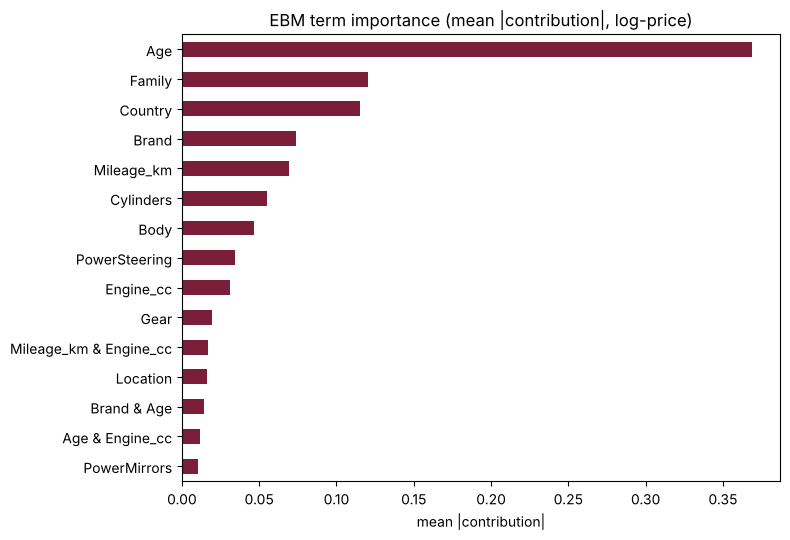

Interaction terms learned: ['Brand & Age', 'Age & Engine_cc', 'Age & Cylinders', 'Age & Country', 'Mileage_km & Engine_cc']


In [6]:
reg = model.regressor_
imp = pd.Series(reg.term_importances(), index=reg.term_names_).sort_values()
ax = imp.tail(15).plot.barh(figsize=(8, 5.5), color="#7A1E3A")
ax.set(title="EBM term importance (mean |contribution|, log-price)", xlabel="mean |contribution|")
plt.tight_layout(); plt.savefig(f"{FIG}/14_ebm_importance.png", dpi=150); plt.show()
print("Interaction terms learned:", [t for t in reg.term_names_ if " & " in t])

**Shape functions:** the learned curves for age and mileage. These are the model itself, not an approximation.

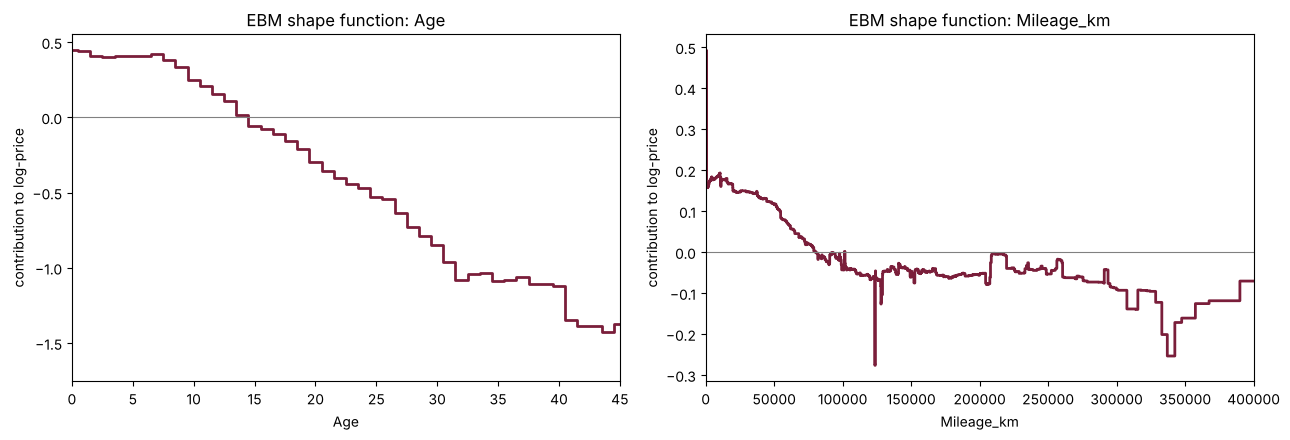

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat, xmax in [(axes[0], "Age", 45), (axes[1], "Mileage_km", 400000)]:
    k = reg.term_names_.index(feat)
    edges = np.asarray(reg.bins_[FEATURES.index(feat)][0])
    scores = np.asarray(reg.term_scores_[k])[1:-1]           # drop the 'missing' and 'unknown' bins
    xs = np.concatenate([[edges[0] - (edges[1] - edges[0])], edges])
    n = min(len(xs), len(scores))
    ax.step(xs[:n], scores[:n], where="post", color="#7A1E3A", lw=2)
    ax.axhline(0, color="grey", lw=0.8); ax.set_xlim(0, xmax)
    ax.set(title=f"EBM shape function: {feat}", xlabel=feat, ylabel="contribution to log-price")
plt.tight_layout(); plt.savefig(f"{FIG}/15_ebm_shape_age_mileage.png", dpi=150); plt.show()

## 5. Does EBM agree with SHAP on the deployed CatBoost model?
CatBoost is refitted on the same training set with its tuned parameters, and SHAP is computed on the same test cars. If two very different models (a black box explained after the fact and a glass box) rank features the same way, the explanation is more trustworthy.

In [8]:
import shap
cb = train.build_model().fit(X_train, y_train)
sv = shap.TreeExplainer(cb.regressor_.model_)(X_test)
shap_rank = pd.Series(np.abs(sv.values).mean(0), index=FEATURES)
ebm_main = imp[[t for t in imp.index if " & " not in t]]
cmp = pd.DataFrame({"EBM importance": ebm_main, "CatBoost mean |SHAP|": shap_rank})
cmp["EBM rank"] = cmp["EBM importance"].rank(ascending=False).astype(int)
cmp["SHAP rank"] = cmp["CatBoost mean |SHAP|"].rank(ascending=False).astype(int)
cmp = cmp.sort_values("SHAP rank").round(3)
from scipy.stats import spearmanr
rho = spearmanr(cmp["EBM rank"], cmp["SHAP rank"]).correlation
print(f"Spearman rank correlation between EBM and SHAP feature rankings: {rho:.2f}")
display(cmp)

Spearman rank correlation between EBM and SHAP feature rankings: 0.77


,EBM importance,CatBoost mean |SHAP|,EBM rank,SHAP rank
Age,0.368,0.339,1,1
Brand,0.074,0.112,4,2
Body,0.047,0.065,7,3
Country,0.115,0.058,3,4
Engine_cc,0.031,0.055,9,5
Mileage_km,0.069,0.050,5,6
Family,0.120,0.039,2,7
PowerSteering,0.034,0.019,8,8
Cylinders,0.055,0.019,6,9
PowerMirrors,0.010,0.015,12,10


## 6. Local explanation: the same 2002 Mitsubishi Lancer
The report explains this car with SHAP and LIME. EBM's local explanation is exact: the contributions add up to the prediction.

{'Brand': 'MITSUBISHI', 'Family': 'MITSUBISHI LANCER', 'Age': 24, 'Mileage_km': 150000.0, 'Location': 'Kolonnawa'}
Actual Rs 5.50M · EBM predicts Rs 5.11M · intercept 2.056 + contributions -0.425 = 1.631 log-price


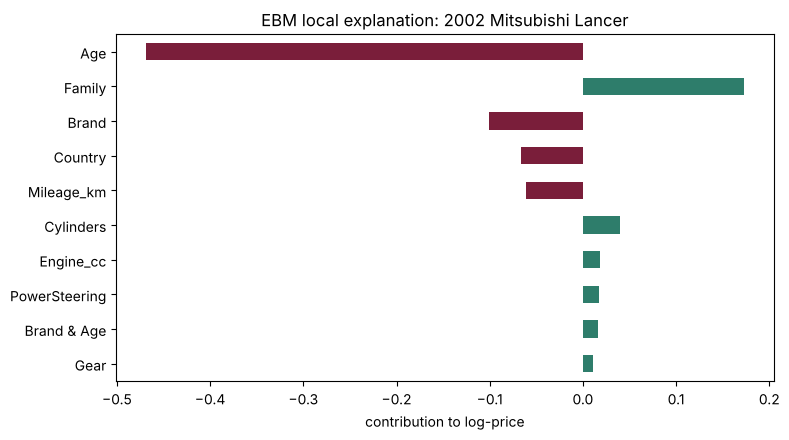

In [9]:
mask = (X_test["Family"].str.contains("LANCER")) & (X_test["Age"] == 24) & (X_test["Mileage_km"].between(149000, 151000))
pos = int(np.where(mask.values)[0][0]) if mask.any() else int(np.argsort(err.values)[len(err) // 2])
car = X_test.iloc[[pos]]
contrib = pd.Series(reg.eval_terms(car)[0], index=reg.term_names_)
top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(10)
print(car.iloc[0][["Brand", "Family", "Age", "Mileage_km", "Location"]].to_dict())
print(f"Actual Rs {y_test.iloc[pos]:.2f}M · EBM predicts Rs {pred[pos]:.2f}M · intercept {reg.intercept_:.3f} + contributions {contrib.sum():.3f} = {reg.intercept_ + contrib.sum():.3f} log-price")
ax = top[::-1].plot.barh(figsize=(8, 4.5), color=["#2E7D6B" if v > 0 else "#7A1E3A" for v in top[::-1]])
ax.set(title="EBM local explanation: 2002 Mitsubishi Lancer", xlabel="contribution to log-price")
plt.tight_layout(); plt.savefig(f"{FIG}/16_ebm_local_lancer.png", dpi=150); plt.show()

## 7. Conclusion
* **Accuracy.** EBM reached the highest cross-validated R² of all models (0.885 ± 0.039, CatBoost 0.885 ± 0.050), with the smallest spread across folds. On the 997 test cars it scored R² 0.920 with a 6.7% median error, slightly behind the tree ensembles (0.928–0.940) but well ahead of Ridge (0.825) and the "compare similar ads" baseline (0.848). A glass-box model is therefore almost as accurate as the black boxes on this problem.
* **Explanations agree.** EBM's exact feature importances rank features much like SHAP on CatBoost (Spearman 0.77), and both put age far ahead of everything else. EBM's own mileage curve flattens beyond about 100,000 km, which independently confirms the threshold found with SHAP.
* **Deployment decision.** The deployed model is chosen on cross-validation, never on the test set. EBM and CatBoost are tied on CV R² (a difference of 0.0006, about 1/60 of the fold-to-fold standard deviation), so the tie is broken on the other cross-validated metric, MAE: CatBoost Rs 0.83M against EBM Rs 0.90M. CatBoost therefore stays deployed, and EBM serves as the interpretable new algorithm and an independent check on what the deployed model learned.